# **Модульна контрольна робота № 2**

In [1]:
import cv2
import math
import numpy as np
from matplotlib import pyplot as plt

plt.rcParams['figure.figsize'] = [15, 10]

### 1. Завантаження зображення

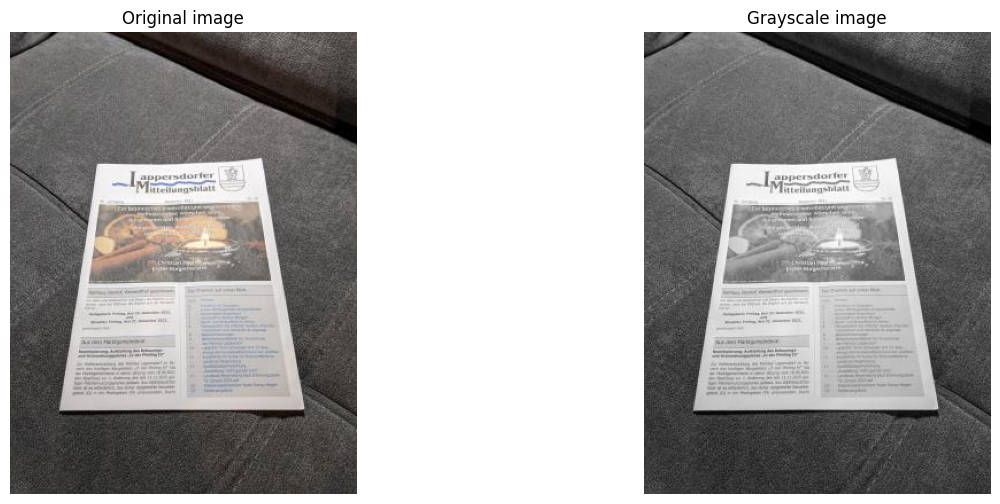

In [2]:
img = cv2.imread('document.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = np.float32(gray) / 255

rows, cols = gray.shape

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 6))

plt.subplot(121)
plt.imshow(img_rgb)
plt.title('Original image')
plt.axis('off')

plt.subplot(122)
plt.imshow(gray, cmap='gray')
plt.title('Grayscale image')
plt.axis('off')

plt.show()

### 2. Відображення кутів документа

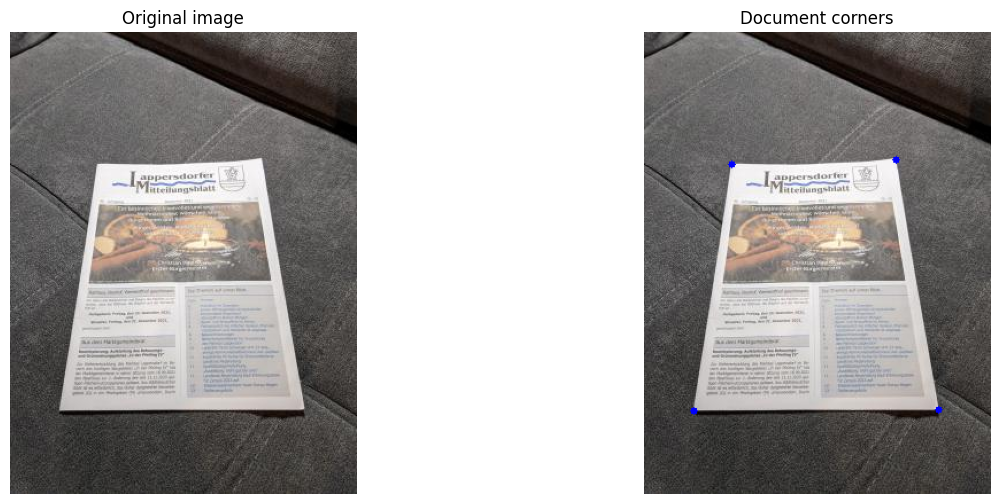

In [3]:
top_left = [76, 115]
top_right = [219, 111]
bottom_left = [43, 330]
bottom_right = [256, 329]

out = np.copy(img)

out = cv2.circle(out, tuple(top_left), 3, (255, 0, 0), -1)
out = cv2.circle(out, tuple(top_right), 3, (255, 0, 0), -1)
out = cv2.circle(out, tuple(bottom_left), 3, (255, 0, 0), -1)
out = cv2.circle(out, tuple(bottom_right), 3, (255, 0, 0), -1)

out_rgb = cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 6))

plt.subplot(121)
plt.imshow(img_rgb)
plt.title('Original image')
plt.axis('off')

plt.subplot(122)
plt.imshow(out_rgb)
plt.title('Document corners')
plt.axis('off')

plt.show()

### 3. Визначення матриць src та dst

In [4]:
src = np.array([
    top_left,
    top_right,
    bottom_left,
    bottom_right
], dtype=np.float32)

dst = np.array([
    [0, 0],
    [cols - 1, 0],
    [0, rows - 1],
    [cols - 1, rows - 1]
], dtype=np.float32)

print("Source points:")
print(src)

print("\nDestination points:")
print(dst)

Source points:
[[ 76. 115.]
 [219. 111.]
 [ 43. 330.]
 [256. 329.]]

Destination points:
[[  0.   0.]
 [301.   0.]
 [  0. 402.]
 [301. 402.]]


### 4. Афінне перетворення 

Affine transformation matrix (first 3 points):
[[ 2.11397119e+00  3.24469996e-01 -1.97975860e+02]
 [ 5.25267043e-02  1.87782968e+00 -2.19942443e+02]]


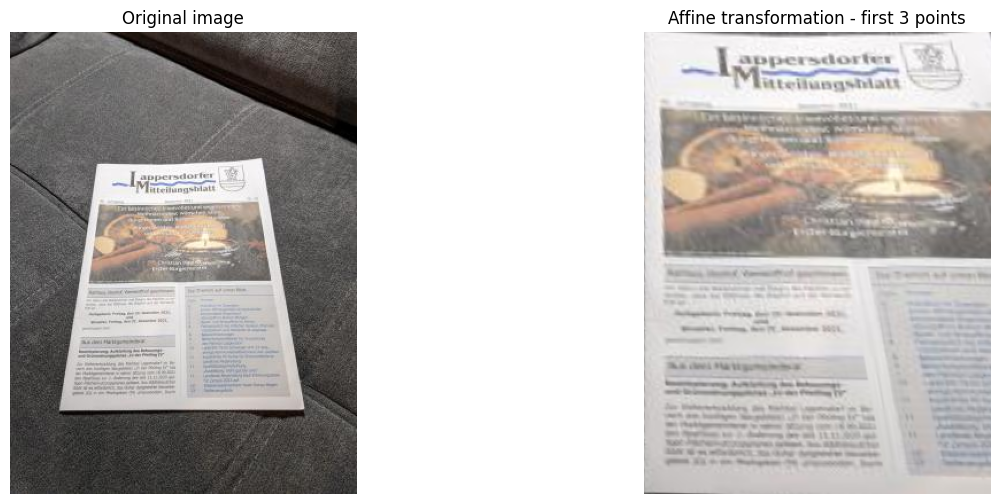

In [5]:
M = cv2.getAffineTransform(src[:3], dst[:3])

print("Affine transformation matrix (first 3 points):")
print(M)

rectified = cv2.warpAffine(img, M, (cols, rows))

rectified_rgb = cv2.cvtColor(rectified, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 6))

plt.subplot(121)
plt.imshow(img_rgb)
plt.title('Original image')
plt.axis('off')

plt.subplot(122)
plt.imshow(rectified_rgb)
plt.title('Affine transformation - first 3 points')
plt.axis('off')

plt.show()

Affine transformation matrix (last 3 points):
[[ 1.41202040e+00 -2.39654839e-01  1.83692195e+01]
 [ 8.65055626e-03  1.84256848e+00 -2.06419573e+02]]


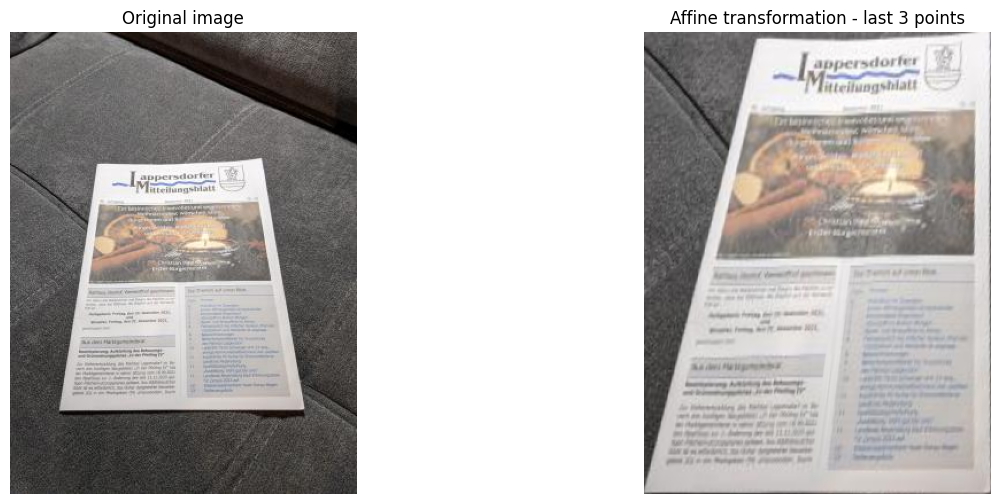

In [6]:
M = cv2.getAffineTransform(src[1:], dst[1:])

print("Affine transformation matrix (last 3 points):")
print(M)

rectified = cv2.warpAffine(img, M, (cols, rows))

rectified_rgb = cv2.cvtColor(rectified, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 6))

plt.subplot(121)
plt.imshow(img_rgb)
plt.title('Original image')
plt.axis('off')

plt.subplot(122)
plt.imshow(rectified_rgb)
plt.title('Affine transformation - last 3 points')
plt.axis('off')

plt.show()

Estimated affine transformation matrix:
[[ 2.09494924e+00 -3.55564779e-01 -1.18326192e+02]
 [ 5.13377179e-02  1.83532341e+00 -2.14963859e+02]]

Inliers vector:
[[1]
 [1]
 [0]
 [1]]


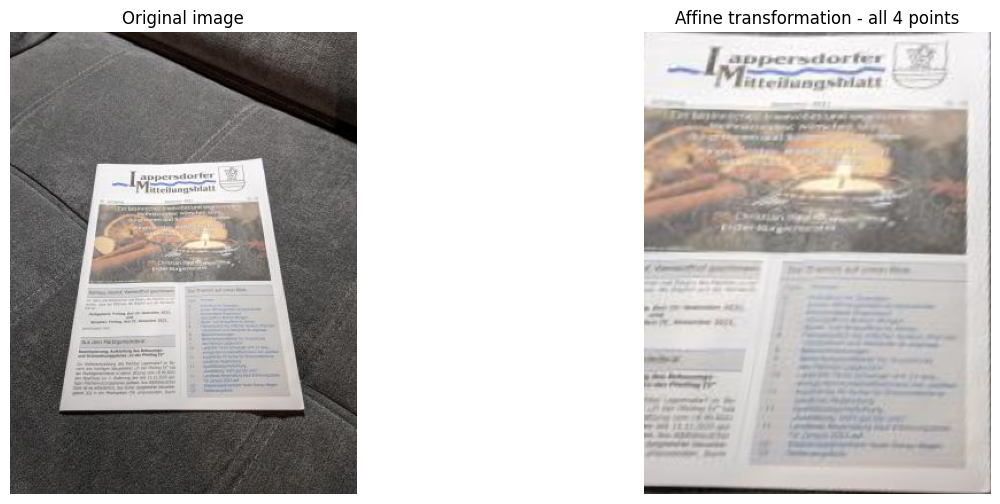

In [7]:
M, inliers = cv2.estimateAffine2D(
    src,
    dst,
    method=cv2.RANSAC
)

print("Estimated affine transformation matrix:")
print(M)

print("\nInliers vector:")
print(inliers)

rectified = cv2.warpAffine(img, M, (cols, rows))

rectified_rgb = cv2.cvtColor(rectified, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 6))

plt.subplot(121)
plt.imshow(img_rgb)
plt.title('Original image')
plt.axis('off')

plt.subplot(122)
plt.imshow(rectified_rgb)
plt.title('Affine transformation - all 4 points')
plt.axis('off')

plt.show()

### 5. Перспективне перетворення (Homography)

Homography transformation matrix:
[[ 2.96021029e+00  4.54357858e-01 -2.77227135e+02]
 [ 1.07463050e-01  3.84180405e+00 -4.49974657e+02]
 [ 2.37188082e-04  3.13841065e-03  1.00000000e+00]]


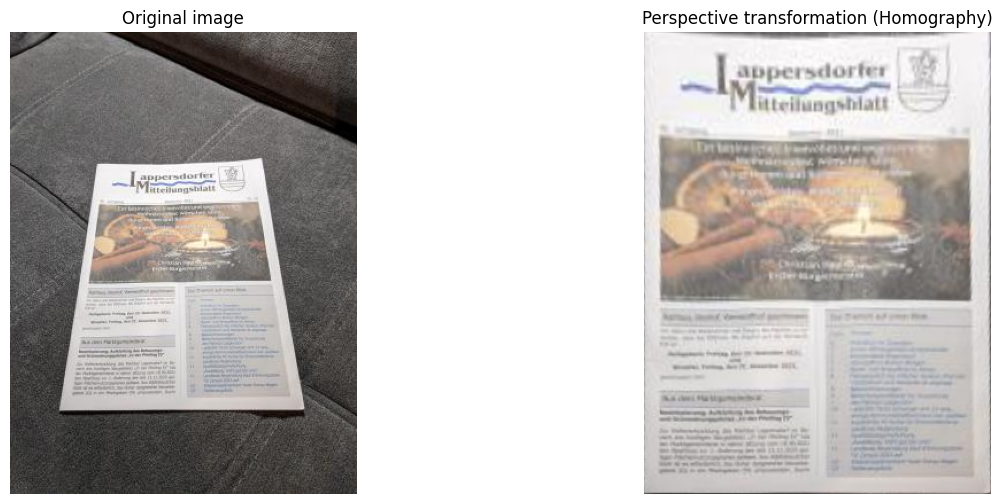

In [8]:
M = cv2.getPerspectiveTransform(src, dst)

print("Homography transformation matrix:")
print(M)

rectified = cv2.warpPerspective(img, M, (cols, rows))

rectified_rgb = cv2.cvtColor(rectified, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 6))

plt.subplot(121)
plt.imshow(img_rgb)
plt.title('Original image')
plt.axis('off')

plt.subplot(122)
plt.imshow(rectified_rgb)
plt.title('Perspective transformation (Homography)')
plt.axis('off')

plt.show()

### 6. Порівняння результатів

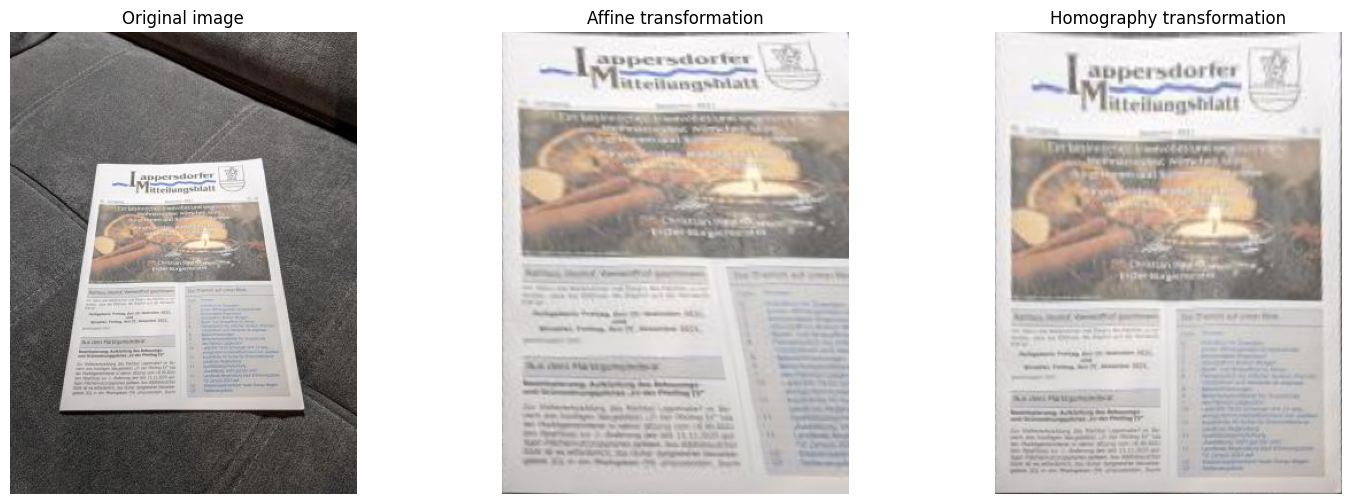

In [9]:
M_affine = cv2.getAffineTransform(src[:3], dst[:3])
affine_result = cv2.warpAffine(img, M_affine, (cols, rows))

M_homography = cv2.getPerspectiveTransform(src, dst)
homography_result = cv2.warpPerspective(
    img, M_homography, (cols, rows)
)

plt.figure(figsize=(18, 6))

plt.subplot(131)
plt.imshow(img_rgb)
plt.title('Original image')
plt.axis('off')

plt.subplot(132)
plt.imshow(cv2.cvtColor(affine_result, cv2.COLOR_BGR2RGB))
plt.title('Affine transformation')
plt.axis('off')

plt.subplot(133)
plt.imshow(cv2.cvtColor(homography_result, cv2.COLOR_BGR2RGB))
plt.title('Homography transformation')
plt.axis('off')

plt.show()